# 03 — Basket Construction and Baseline Portfolio

## Project: Improving Basket Trading Using Bayesian Optimization

### Objective
Construct a baseline ETF portfolio and prepare a chronological train/test split for subsequent Bayesian Optimization.

### Portfolio Universe
- XLK — Technology
- XLF — Financials
- XLE — Energy
- XLI — Industrials
- XLP — Consumer Staples

### Methodology
1. Load historical ETF prices.
2. Calculate daily percentage returns.
3. Split observations chronologically into training and testing periods.
4. Construct an equal-weight portfolio.
5. Evaluate baseline risk and return metrics.

### Portfolio Constraints
- Long-only positions
- Fully invested portfolio
- Portfolio weights sum to 1
- No leverage

The portfolio will be evaluated out of sample. Transaction costs and rebalancing assumptions will be documented explicitly.

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project paths
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "etf_prices.csv"

# Load prices
prices = pd.read_csv(
    DATA_PATH,
    index_col="Date",
    parse_dates=True
)

# Calculate daily returns
returns = prices.pct_change().dropna()

# Chronological train/test split
split_idx = int(len(returns) * 0.75)

train_returns = returns.iloc[:split_idx].copy()
test_returns = returns.iloc[split_idx:].copy()

print("Training observations:", len(train_returns))
print("Testing observations:", len(test_returns))

print("\nTraining period:")
print(train_returns.index.min(), "to", train_returns.index.max())

print("\nTesting period:")
print(test_returns.index.min(), "to", test_returns.index.max())

Training observations: 2228
Testing observations: 743

Training period:
2015-01-05 00:00:00 to 2023-11-08 00:00:00

Testing period:
2023-11-09 00:00:00 to 2026-10-27 00:00:00


In [14]:
# Equal-weight portfolio
n_assets = len(train_returns.columns)

equal_weights = np.ones(n_assets) / n_assets

weights_df = pd.DataFrame({
    "ETF": train_returns.columns,
    "Weight": equal_weights
})

display(weights_df)

print("Total weight:", equal_weights.sum())

,ETF,Weight
0,XLK,0.2
1,XLF,0.2
2,XLE,0.2
3,XLI,0.2
4,XLP,0.2


Total weight: 1.0


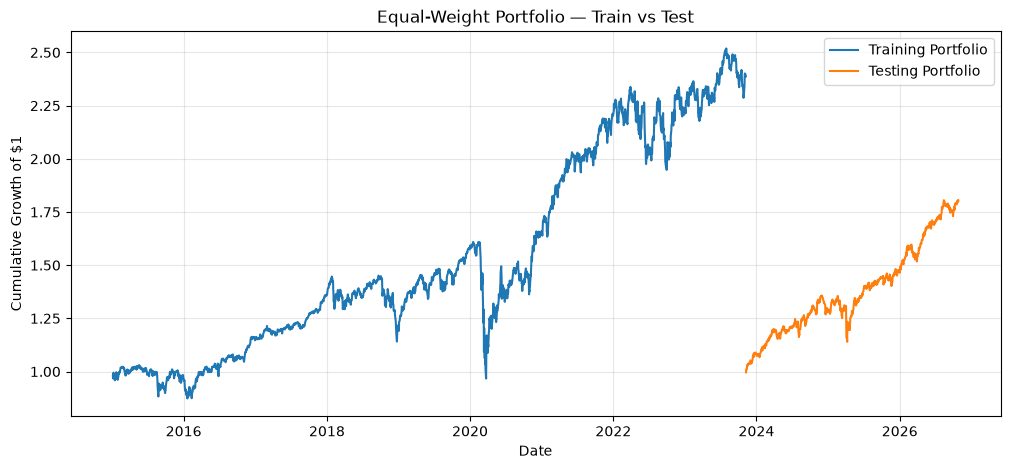

In [15]:
# Portfolio daily returns
train_portfolio_returns = train_returns @ equal_weights
test_portfolio_returns = test_returns @ equal_weights

# Cumulative growth of $1
train_cumulative = (1 + train_portfolio_returns).cumprod()
test_cumulative = (1 + test_portfolio_returns).cumprod()

# Plot
plt.figure(figsize=(12, 5))

plt.plot(
    train_cumulative,
    label="Training Portfolio"
)

plt.plot(
    test_cumulative,
    label="Testing Portfolio"
)

plt.title("Equal-Weight Portfolio — Train vs Test")
plt.xlabel("Date")
plt.ylabel("Cumulative Growth of $1")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [16]:
def portfolio_metrics(daily_returns, risk_free_rate=0.0):
    annual_factor = 252

    cumulative = (1 + daily_returns).cumprod()

    annual_return = (
        cumulative.iloc[-1] ** (annual_factor / len(daily_returns))
    ) - 1

    annual_volatility = daily_returns.std() * np.sqrt(annual_factor)

    sharpe_ratio = (
        (daily_returns.mean() * annual_factor - risk_free_rate)
        / annual_volatility
        if annual_volatility > 0 else np.nan
    )

    wealth = pd.concat([
        pd.Series([1.0]),
        cumulative.reset_index(drop=True)
    ], ignore_index=True)

    drawdown = wealth / wealth.cummax() - 1
    max_drawdown = drawdown.min()

    return {
        "Annualized Return": annual_return,
        "Annualized Volatility": annual_volatility,
        "Sharpe Ratio": sharpe_ratio,
        "Max Drawdown": max_drawdown
    }


baseline_results = pd.DataFrame({
    "Train": portfolio_metrics(train_portfolio_returns),
    "Test": portfolio_metrics(test_portfolio_returns)
})

display(baseline_results.round(4))

,Train,Test
Annualized Return,0.1034,0.2214
Annualized Volatility,0.1929,0.1282
Sharpe Ratio,0.6073,1.6251
Max Drawdown,-0.3990,-0.1604


- **Annualized Return:** During the Train, the portfolio estimated growth went from 10,34% to 22,14% during the Test.

- **Annualized Volatility:** The volatility went down from 19,29% to 12,82% indicading the daily return had less variation during the Test.

- **Sharpe Ratio:** The Sharpe went from 0,61 to 1,63 which means a better relation between volatility and return during the second period.

- **Max Drawdown:** During the Training, the portfolio had a max drawdown close to 40% and during the Test the max drawdown is close to 16%.

## 6. Bayesian Optimization of Portfolio Weights

The objective is to maximize the portfolio's in-sample Sharpe Ratio using Bayesian Optimization with Optuna's TPE sampler.
The optimization is performed exclusively on the training dataset.

Portfolio constraints:
- Long-only allocation
- Fully invested portfolio
- Weights sum to one
- No leverage

The optimized portfolio will subsequently be evaluated on the untouched test dataset and compared against the equal-weight baseline.
A higher training Sharpe Ratio does not guarantee better out-of-sample performance.

In [17]:
import optuna

def objective(trial):

    # Suggest five non-negative raw weights
    raw_weights = np.array([
        trial.suggest_float(f"weight_{etf}", 0.001, 1.0)
        for etf in train_returns.columns
    ])

    # Normalize weights to sum to 1
    weights = raw_weights / raw_weights.sum()

    # Training portfolio returns
    portfolio_returns = train_returns @ weights

    # Annualized Sharpe Ratio (risk-free rate = 0)
    annual_return = portfolio_returns.mean() * 252
    annual_volatility = portfolio_returns.std() * np.sqrt(252)

    if annual_volatility == 0:
        return -1e6

    sharpe = annual_return / annual_volatility

    return sharpe

/Users/ady/Proyectos/bayesian-basket-trading/.venv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [18]:
# Create optimization study
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

# Run 200 trials
study.optimize(
    objective,
    n_trials=200,
    show_progress_bar=True
)

print("Best Training Sharpe:", round(study.best_value, 4))
print("\nBest raw parameters:")
print(study.best_params)

[I 2026-11-14 15:06:23,927] A new study created in memory with name: no-name-8d0905b2-83d5-47bf-8452-d7b9cd13b016
Best trial: 38. Best value: 0.852428:  32%|███▏      | 63/200 [00:00<00:00, 304.83it/s]

[I 2026-11-14 15:06:24,059] Trial 0 finished with value: 0.5347110520702486 and parameters: {'weight_XLK': 0.37516557872851514, 'weight_XLF': 0.9507635921035062, 'weight_XLE': 0.7322619478695936, 'weight_XLI': 0.5990598257128396, 'weight_XLP': 0.1568626218019941}. Best is trial 0 with value: 0.5347110520702486.
[I 2026-11-14 15:06:24,061] Trial 1 finished with value: 0.5057053312905545 and parameters: {'weight_XLK': 0.15683852581586644, 'weight_XLF': 0.05902552855603126, 'weight_XLE': 0.8663099696291603, 'weight_XLI': 0.6015138967314656, 'weight_XLP': 0.7083645052182495}. Best is trial 0 with value: 0.5347110520702486.
[I 2026-11-14 15:06:24,074] Trial 2 finished with value: 0.43941422096103067 and parameters: {'weight_XLK': 0.021563909801506645, 'weight_XLF': 0.9699399423098324, 'weight_XLE': 0.8326101981596213, 'weight_XLI': 0.21312677156759788, 'weight_XLP': 0.18264314223989353}. Best is trial 0 with value: 0.5347110520702486.
[I 2026-11-14 15:06:24,077] Trial 3 finished with value:

Best trial: 96. Best value: 0.862815:  56%|█████▋    | 113/200 [00:00<00:00, 283.19it/s]

[I 2026-11-14 15:06:24,264] Trial 64 finished with value: 0.8206547309754612 and parameters: {'weight_XLK': 0.7885332156472488, 'weight_XLF': 0.11549328802765665, 'weight_XLE': 0.037803790293473256, 'weight_XLI': 0.050135082312387884, 'weight_XLP': 0.18317794515158875}. Best is trial 38 with value: 0.8524277955538717.
[I 2026-11-14 15:06:24,267] Trial 65 finished with value: 0.8073961079727575 and parameters: {'weight_XLK': 0.7047262793561895, 'weight_XLF': 0.18340018214603637, 'weight_XLE': 0.04683263333867739, 'weight_XLI': 0.009224924327438773, 'weight_XLP': 0.125326697578729}. Best is trial 38 with value: 0.8524277955538717.
[I 2026-11-14 15:06:24,270] Trial 66 finished with value: 0.7941549653867168 and parameters: {'weight_XLK': 0.8174926326529203, 'weight_XLF': 0.08224109477618974, 'weight_XLE': 0.16843595921138818, 'weight_XLI': 0.08874010500946947, 'weight_XLP': 0.10373927165144531}. Best is trial 38 with value: 0.8524277955538717.
[I 2026-11-14 15:06:24,274] Trial 67 finished

Best trial: 129. Best value: 0.865174:  78%|███████▊  | 155/200 [00:00<00:00, 236.50it/s]

[I 2026-11-14 15:06:24,468] Trial 114 finished with value: 0.8353679857215229 and parameters: {'weight_XLK': 0.8596962513979619, 'weight_XLF': 0.003159612922765115, 'weight_XLE': 0.09630693369368512, 'weight_XLI': 0.07868377074356549, 'weight_XLP': 0.0021322037058511614}. Best is trial 96 with value: 0.8628149000228008.
[I 2026-11-14 15:06:24,472] Trial 115 finished with value: 0.8412575136564528 and parameters: {'weight_XLK': 0.8887120314794891, 'weight_XLF': 0.030922958602870552, 'weight_XLE': 0.012097756790596825, 'weight_XLI': 0.13977893822335943, 'weight_XLP': 0.019633925361086105}. Best is trial 96 with value: 0.8628149000228008.
[I 2026-11-14 15:06:24,476] Trial 116 finished with value: 0.8285507143853473 and parameters: {'weight_XLK': 0.7950819645258513, 'weight_XLF': 0.06679938451717132, 'weight_XLE': 0.09306852068948675, 'weight_XLI': 0.0013372607809468869, 'weight_XLP': 0.09980093944090496}. Best is trial 96 with value: 0.8628149000228008.
[I 2026-11-14 15:06:24,482] Trial 1

Best trial: 129. Best value: 0.865174: 100%|██████████| 200/200 [00:00<00:00, 244.30it/s]

[I 2026-11-14 15:06:24,669] Trial 156 finished with value: 0.8372807964160687 and parameters: {'weight_XLK': 0.9457662136768654, 'weight_XLF': 0.021059314855027544, 'weight_XLE': 0.06629299127200398, 'weight_XLI': 0.05885338532607903, 'weight_XLP': 0.19329196000718257}. Best is trial 129 with value: 0.8651741251599657.
[I 2026-11-14 15:06:24,673] Trial 157 finished with value: 0.8505630076613148 and parameters: {'weight_XLK': 0.8479097547870081, 'weight_XLF': 0.011019744028962724, 'weight_XLE': 0.06426999809805536, 'weight_XLI': 0.0014351655175764066, 'weight_XLP': 0.06797631038782422}. Best is trial 129 with value: 0.8651741251599657.
[I 2026-11-14 15:06:24,678] Trial 158 finished with value: 0.8519367140158167 and parameters: {'weight_XLK': 0.9928740679152971, 'weight_XLF': 0.012608104855058075, 'weight_XLE': 0.008016456817335975, 'weight_XLI': 0.09132834434363225, 'weight_XLP': 0.07875272271413997}. Best is trial 129 with value: 0.8651741251599657.
[I 2026-11-14 15:06:24,697] Trial 

In [19]:
raw_best_weights = np.array([
    study.best_params[f"weight_{etf}"]
    for etf in train_returns.columns
])

optimized_weights = raw_best_weights / raw_best_weights.sum()

optimized_weights_df = pd.DataFrame({
    "ETF": train_returns.columns,
    "Baseline Weight": equal_weights,
    "Optimized Weight": optimized_weights
})

display(optimized_weights_df.round(4))

print("Total optimized weight:", optimized_weights.sum())

,ETF,Baseline Weight,Optimized Weight
0,XLK,0.2,0.9459
1,XLF,0.2,0.0135
2,XLE,0.2,0.0016
3,XLI,0.2,0.0046
4,XLP,0.2,0.0344


Total optimized weight: 1.0


In [21]:
# Optimized portfolio daily returns
optimized_train_returns = train_returns @ optimized_weights
optimized_test_returns = test_returns @ optimized_weights

# Calculate metrics
optimized_results = pd.DataFrame({
    "Train": portfolio_metrics(optimized_train_returns),
    "Test": portfolio_metrics(optimized_test_returns)
})

display(optimized_results.round(4))

,Train,Test
Annualized Return,0.1877,0.2994
Annualized Volatility,0.2294,0.2413
Sharpe Ratio,0.8652,1.2061
Max Drawdown,-0.3246,-0.2483


In [22]:
comparison = pd.DataFrame({
    "Baseline Train": portfolio_metrics(train_portfolio_returns),
    "Optimized Train": portfolio_metrics(optimized_train_returns),
    "Baseline Test": portfolio_metrics(test_portfolio_returns),
    "Optimized Test": portfolio_metrics(optimized_test_returns)
})

display(comparison.round(4))

,Baseline Train,Optimized Train,Baseline Test,Optimized Test
Annualized Return,0.1034,0.1877,0.2214,0.2994
Annualized Volatility,0.1929,0.2294,0.1282,0.2413
Sharpe Ratio,0.6073,0.8652,1.6251,1.2061
Max Drawdown,-0.3990,-0.3246,-0.1604,-0.2483


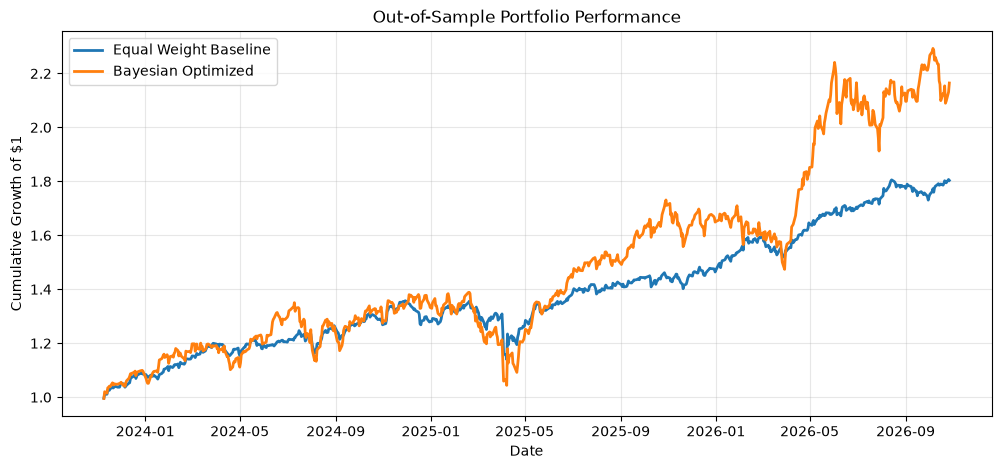

In [23]:
# Cumulative growth of $1 during Test
baseline_test_growth = (1 + test_portfolio_returns).cumprod()
optimized_test_growth = (1 + optimized_test_returns).cumprod()

plt.figure(figsize=(12, 5))

plt.plot(
    baseline_test_growth,
    label="Equal Weight Baseline",
    linewidth=2
)

plt.plot(
    optimized_test_growth,
    label="Bayesian Optimized",
    linewidth=2
)

plt.title("Out-of-Sample Portfolio Performance")
plt.xlabel("Date")
plt.ylabel("Cumulative Growth of $1")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [24]:
from scipy.special import expit

MAX_WEIGHT = 0.40

def constrained_weights(trial):
    # Sequentially allocate weights while preserving feasibility
    weights = []
    remaining = 1.0
    n = len(train_returns.columns)

    for i in range(n - 1):
        remaining_assets = n - i - 1

        lower = max(
            0.0,
            remaining - remaining_assets * MAX_WEIGHT
        )
        upper = min(MAX_WEIGHT, remaining)

        fraction = trial.suggest_float(f"fraction_{i}", 0.0, 1.0)
        weight = lower + fraction * (upper - lower)

        weights.append(weight)
        remaining -= weight

    weights.append(remaining)

    return np.array(weights)


def constrained_objective(trial):
    weights = constrained_weights(trial)

    portfolio_returns = train_returns @ weights

    annual_volatility = (
        portfolio_returns.std() * np.sqrt(252)
    )

    if annual_volatility <= 0:
        return -1e6

    sharpe = (
        portfolio_returns.mean() * 252
    ) / annual_volatility

    return sharpe

In [25]:
constrained_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

constrained_study.optimize(
    constrained_objective,
    n_trials=300,
    show_progress_bar=True
)

constrained_best_weights = constrained_weights(
    constrained_study.best_trial
)

constrained_weights_df = pd.DataFrame({
    "ETF": train_returns.columns,
    "Equal Weight": equal_weights,
    "Unconstrained": optimized_weights,
    "Constrained": constrained_best_weights
})

display(constrained_weights_df.round(4))

print(
    "Best Constrained Train Sharpe:",
    round(constrained_study.best_value, 4)
)

print("Sum of weights:", constrained_best_weights.sum())
print("Maximum weight:", constrained_best_weights.max())

[I 2026-11-14 15:24:15,194] A new study created in memory with name: no-name-5e5f1932-7d4e-4d8c-a2c0-175f4ad6ee3e
Best trial: 22. Best value: 0.759506:  24%|██▍       | 72/300 [00:00<00:00, 357.78it/s]

[I 2026-11-14 15:24:15,203] Trial 0 finished with value: 0.5321915079455929 and parameters: {'fraction_0': 0.3745401188473625, 'fraction_1': 0.9507143064099162, 'fraction_2': 0.7319939418114051, 'fraction_3': 0.5986584841970366}. Best is trial 0 with value: 0.5321915079455929.
[I 2026-11-14 15:24:15,205] Trial 1 finished with value: 0.5785269575452642 and parameters: {'fraction_0': 0.15601864044243652, 'fraction_1': 0.15599452033620265, 'fraction_2': 0.05808361216819946, 'fraction_3': 0.8661761457749352}. Best is trial 1 with value: 0.5785269575452642.
[I 2026-11-14 15:24:15,207] Trial 2 finished with value: 0.643587352337032 and parameters: {'fraction_0': 0.6011150117432088, 'fraction_1': 0.7080725777960455, 'fraction_2': 0.020584494295802447, 'fraction_3': 0.9699098521619943}. Best is trial 2 with value: 0.643587352337032.
[I 2026-11-14 15:24:15,213] Trial 3 finished with value: 0.7211286379571165 and parameters: {'fraction_0': 0.8324426408004217, 'fraction_1': 0.21233911067827616, '

Best trial: 92. Best value: 0.76264:  43%|████▎     | 129/300 [00:00<00:00, 326.43it/s]

[I 2026-11-14 15:24:15,407] Trial 73 finished with value: 0.7550674959777413 and parameters: {'fraction_0': 0.9646126784064144, 'fraction_1': 0.12028734499169037, 'fraction_2': 0.0057126304959582075, 'fraction_3': 0.14765989341801045}. Best is trial 22 with value: 0.7595055491088126.
[I 2026-11-14 15:24:15,409] Trial 74 finished with value: 0.727826429684487 and parameters: {'fraction_0': 0.8159637971028945, 'fraction_1': 0.12879657852715812, 'fraction_2': 0.10273029964693603, 'fraction_3': 0.048410048655635494}. Best is trial 22 with value: 0.7595055491088126.
[I 2026-11-14 15:24:15,411] Trial 75 finished with value: 0.7457660586212487 and parameters: {'fraction_0': 0.9299991260289435, 'fraction_1': 0.04269551175808159, 'fraction_2': 0.14638138080726296, 'fraction_3': 0.09727738083892587}. Best is trial 22 with value: 0.7595055491088126.
[I 2026-11-14 15:24:15,415] Trial 76 finished with value: 0.7515917240656681 and parameters: {'fraction_0': 0.9637589074155322, 'fraction_1': 0.12241

Best trial: 175. Best value: 0.76277:  59%|█████▉    | 178/300 [00:00<00:00, 269.80it/s]

[I 2026-11-14 15:24:15,610] Trial 130 finished with value: 0.7558755950690368 and parameters: {'fraction_0': 0.9682912650783109, 'fraction_1': 0.024887619703000574, 'fraction_2': 0.004773963840947755, 'fraction_3': 0.26282291849291106}. Best is trial 92 with value: 0.7626396757622916.
[I 2026-11-14 15:24:15,614] Trial 131 finished with value: 0.759323684325085 and parameters: {'fraction_0': 0.9985287856778324, 'fraction_1': 0.08934915305555183, 'fraction_2': 0.053695895614221556, 'fraction_3': 0.14014880312011094}. Best is trial 92 with value: 0.7626396757622916.
[I 2026-11-14 15:24:15,620] Trial 132 finished with value: 0.759264012640623 and parameters: {'fraction_0': 0.9822154174956954, 'fraction_1': 0.037345774503299296, 'fraction_2': 0.010807733454888939, 'fraction_3': 0.1520626871052261}. Best is trial 92 with value: 0.7626396757622916.
[I 2026-11-14 15:24:15,625] Trial 133 finished with value: 0.7564432206496707 and parameters: {'fraction_0': 0.9869206659326117, 'fraction_1': 0.0

... (4 outputs left out)

Best trial: 196. Best value: 0.763475: 100%|██████████| 300/300 [00:01<00:00, 267.89it/s]

[I 2026-11-14 15:24:16,223] Trial 278 finished with value: 0.7610014594331387 and parameters: {'fraction_0': 0.9924222606577342, 'fraction_1': 0.021722819205353048, 'fraction_2': 0.045084708526945655, 'fraction_3': 0.08264039780796198}. Best is trial 196 with value: 0.7634754956480371.
[I 2026-11-14 15:24:16,229] Trial 279 finished with value: 0.7524017735117952 and parameters: {'fraction_0': 0.9332788795089211, 'fraction_1': 0.058760167893247846, 'fraction_2': 0.014748863475211323, 'fraction_3': 0.05654713077412976}. Best is trial 196 with value: 0.7634754956480371.
[I 2026-11-14 15:24:16,233] Trial 280 finished with value: 0.7618404174533074 and parameters: {'fraction_0': 0.9925383692117142, 'fraction_1': 0.0695938083871244, 'fraction_2': 0.029990337269312547, 'fraction_3': 0.001963762595211478}. Best is trial 196 with value: 0.7634754956480371.
[I 2026-11-14 15:24:16,239] Trial 281 finished with value: 0.7560350713721531 and parameters: {'fraction_0': 0.9458974021783867, 'fraction_1

,ETF,Equal Weight,Unconstrained,Constrained
0,XLK,0.2,0.9459,0.3973
1,XLF,0.2,0.0135,0.0014
2,XLE,0.2,0.0016,0.0047
3,XLI,0.2,0.0046,0.1974
4,XLP,0.2,0.0344,0.3992


Best Constrained Train Sharpe: 0.7635
Sum of weights: 0.9999999999999999
Maximum weight: 0.39917419419463507


In [26]:
constrained_train_returns = train_returns @ constrained_best_weights
constrained_test_returns = test_returns @ constrained_best_weights

final_comparison = pd.DataFrame({
    "Equal Weight Train": portfolio_metrics(train_portfolio_returns),
    "Unconstrained Train": portfolio_metrics(optimized_train_returns),
    "Constrained Train": portfolio_metrics(constrained_train_returns),
    "Equal Weight Test": portfolio_metrics(test_portfolio_returns),
    "Unconstrained Test": portfolio_metrics(optimized_test_returns),
    "Constrained Test": portfolio_metrics(constrained_test_returns)
})

display(final_comparison.round(4))

,Equal Weight Train,Unconstrained Train,Constrained Train,Equal Weight Test,Unconstrained Test,Constrained Test
Annualized Return,0.1034,0.1877,0.1255,0.2214,0.2994,0.2176
Annualized Volatility,0.1929,0.2294,0.1751,0.1282,0.2413,0.1360
Sharpe Ratio,0.6073,0.8652,0.7635,1.6251,1.2061,1.5164
Max Drawdown,-0.3990,-0.3246,-0.3073,-0.1604,-0.2483,-0.1619


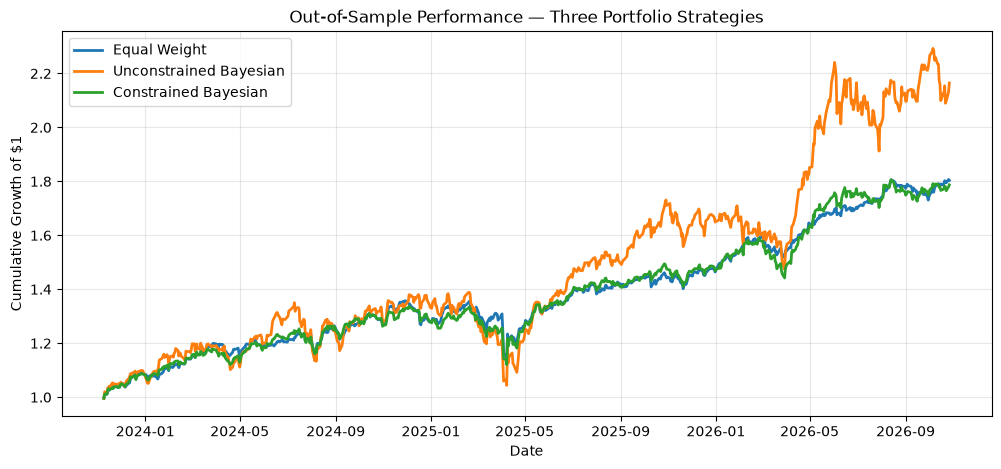

In [27]:
plt.figure(figsize=(12, 5))

strategies = {
    "Equal Weight": test_portfolio_returns,
    "Unconstrained Bayesian": optimized_test_returns,
    "Constrained Bayesian": constrained_test_returns
}

for name, daily_returns in strategies.items():
    growth = (1 + daily_returns).cumprod()
    plt.plot(growth, label=name, linewidth=2)

plt.title("Out-of-Sample Performance — Three Portfolio Strategies")
plt.xlabel("Date")
plt.ylabel("Cumulative Growth of $1")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [28]:
from pathlib import Path

RESULTS_PATH = PROJECT_ROOT / "results"
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

# Save full comparison
final_comparison.to_csv(
    RESULTS_PATH / "portfolio_comparison.csv"
)

# Display test results as percentages where appropriate
test_summary = final_comparison[
    [
        "Equal Weight Test",
        "Unconstrained Test",
        "Constrained Test"
    ]
].copy()

display(test_summary.round(4))

# Save optimized allocations
constrained_weights_df.to_csv(
    RESULTS_PATH / "portfolio_weights.csv",
    index=False
)

print("Results saved successfully.")

,Equal Weight Test,Unconstrained Test,Constrained Test
Annualized Return,0.2214,0.2994,0.2176
Annualized Volatility,0.1282,0.2413,0.1360
Sharpe Ratio,1.6251,1.2061,1.5164
Max Drawdown,-0.1604,-0.2483,-0.1619


Results saved successfully.
